# Heart Failure Mortality Prediction


**Goal:** Predict whether a patient with heart failure died during the follow-up period.

**Dataset:** Heart Failure Clinical Records (Chicco & Jurman, 2020), from the UCI Machine Learning Repository.
It has **299 patients** and **12 clinical features**. The target is `DEATH_EVENT` (1 = died, 0 = survived).

## 1. Load the libraries

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score


## 2. Load the dataset

In [15]:
# Read the CSV file
data = pd.read_csv("heart_failure_clinical_records.csv")

print("Dataset shape (rows, columns):", data.shape)
data.head(10)


Dataset shape (rows, columns): (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1
5,90.0,1,47,0,40,1,204000.00,2.1,132,1,1,8,1
6,75.0,1,246,0,15,0,127000.00,1.2,137,1,0,10,1
7,60.0,1,315,1,60,0,454000.00,1.1,131,1,1,10,1
8,65.0,0,157,0,65,0,263358.03,1.5,138,0,0,10,1
9,80.0,1,123,0,35,1,388000.00,9.4,133,1,1,10,1


In [16]:
print('The Dataset information:') # to check the varibles and their type
data.info()

The Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 3

## 3.Data Check

In [17]:
# Missing values
print("Missing values per column:")
print(data.isnull().sum())

# Duplicate rows
print("\nDuplicate rows:", data.duplicated().sum())

Missing values per column:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

Duplicate rows: 0


We have no missing or duplicated data which will be benificial because we wont need to drop / fill missing data

## 4.Data visualization

A bar graph will be used to compare likelihood of `DEATH_EVENT` from heart failure

Text(0.5, 0, 'Cardiovascular Disease Presence')

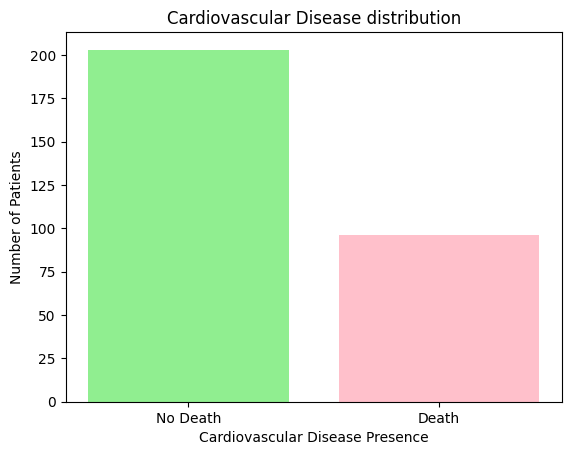

In [18]:
# Death event is categorical so we will use bar
counts = data["DEATH_EVENT"].value_counts()

plt.bar(['No Death','Death'],counts, color=['lightgreen','pink'])

plt.title('Cardiovascular Disease distribution')

plt.ylabel('Number of Patients')

plt.xlabel('Cardiovascular Disease Presence')

**Interpretation** : The bar chart shows the distribution of patients according to the DEATH_EVENT variable. It compares patients who survived with those who experienced a death event. The graph indicates that the number of patients with no recorded death event is higher than the number of patients who experienced a `DEATH_EVENT`. Therefore, the dataset is imbalanced, with more survival cases than death cases.

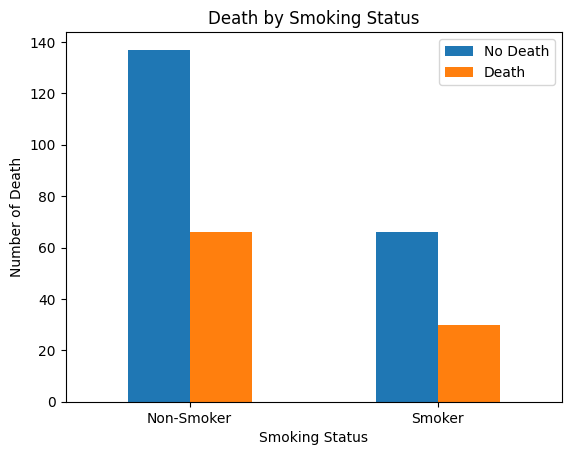

In [27]:
#Smoking compared to death
smoking_counts = pd.crosstab(
    data["smoking"],
    data["DEATH_EVENT"]
)

smoking_counts.plot(
    kind="bar"
)

plt.title("Death by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Death")
plt.xticks([0, 1], ["Non-Smoker", "Smoker"], rotation=0)
plt.legend(["No Death", "Death"])

plt.show()

**Interpretation** : The graph compares death events between non-smokers and smokers. Among non-smokers, 137 patients survived and 66 experienced a death event. Among smokers, 66 patients survived and 30 experienced a death event. Although non-smokers have a higher number of deaths, this is because there are more non-smokers in the dataset. The death proportions are similar in both groups, so this graph does not show a strong relationship between smoking status and death events.”

## 5.Features and target



1.   First we will store FEATURES as X and OUTPUT as Y
2.   **Spit** data into training and test set



In [19]:
X = data.drop(columns = ["DEATH_EVENT"]) #we will store all features as X, cardio and id are not features for prediction
y= data["DEATH_EVENT"] #Y will store the output (classification)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42

)
print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 239 | Test size: 60


## 6.Train the models

**6.1 Logistic Regression**

In [20]:
#to create a model, a pipeline is used to ensure the same scaling method applies to training and test data to prevent leakage
logisticModel = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter = 3000)
)

#model learns patters on train data
logisticModel.fit(X_train , y_train)

#model makes predictions
y_pred_log = logisticModel.predict(X_test)


**6.2 Decision Tree**

In [21]:
DecisionTreeModel = DecisionTreeClassifier(
    max_depth = 5,
    random_state=1)

#Train the model
DecisionTreeModel.fit(X_train , y_train)

#predict class
y_pred_dt = DecisionTreeModel.predict(X_test)


**6.3 KNN**

In [22]:
#scale using pipeline
KnnModel = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=10)
)

#Train the model
KnnModel.fit(X_train , y_train)

#predict class
y_pred_knn = KnnModel.predict(X_test)

## 7.Evaluate

In [23]:
#Create dictionary storing all predicted values:
predictions = {
    "Logistic Regression" : y_pred_log,
    "KNN" : y_pred_knn,
    "Decision tree" : y_pred_dt
}

results = []

for model , pred in predictions.items():
 results.append({
   "Model" : model,

  "Accuracy" : round(accuracy_score(y_test, pred) * 100 , 2),

 "Percision" : round(precision_score(y_test, pred) * 100, 2),

 "Recall" : round(recall_score(y_test, pred) * 100 , 2),

  "F1 score" : round(f1_score(y_test, pred) * 100 , 2)

})



## 8.Compare

In [24]:
#store list as data frame to visualize comparison
results_df = pd.DataFrame(results)
results_df


,Model,Accuracy,Percision,Recall,F1 score
0,Logistic Regression,81.67,78.57,57.89,66.67
1,KNN,73.33,80.00,21.05,33.33
2,Decision tree,68.33,50.00,57.89,53.66


##9.model optimization

Since logistic regression achieved highest accuracy, we will try to optimize model to achieve even higher , better performance

In [25]:


# Create pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000))
])

# Parameters to test
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# Tune the model
grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

# Best model
best_lr = grid_search.best_estimator_

# Test accuracy
y_pred = best_lr.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", round(grid_search.best_score_ * 100, 2), "%")
print("Test Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

Best Parameters: {'model__C': 10}
Best CV Accuracy: 84.09 %
Test Accuracy: 81.67 %
